# BiblioTech — MVP Beta**Instituto Superior Politécnico Córdoba (ISPC)** · Tecnicatura Superior en Ciencia de Datos e IA**Materias:** Testeo de Software y Práctica Profesionalizante I · **Grupo N° 8** · Año 2026**Integrantes:** Mateo Lloveras · Gino Agustin Lencina · Santino Vidal Gallea · Christian Quispe · Pablo Francisco Elias---Este notebook integra todo el flujo del prototipo: **datos → modelo/lógica → interfaz**.| Sección | Qué hace | Requerimiento ||---|---|---|| 1 | Carga de datos y control de calidad | RF1, RF2 || 2 | Análisis exploratorio y gráficos | RF3, RF4, RF5 || 3 | Entrenamiento del modelo de riesgo de mora | RF11 || 4 | Interfaz interactiva (login, catálogo, reservas, usuarios, riesgo, notificaciones, dashboard) | RF6 a RF10 || 5 | Verificación automática de los casos de prueba | Plan de pruebas |Para usarlo en Google Colab: **Entorno de ejecución → Ejecutar todo**. No hace falta editar ninguna celda de código.

## 0. Preparación del entornoSi el notebook corre en Google Colab, esta celda clona el repositorio e instala lo que falte.Si corre en forma local dentro del repositorio, no hace nada.

In [1]:
import subprocess
import sys
from pathlib import Path

REPOSITORIO = "https://github.com/mateolloveras/bibliotech-abp-grupo8.git"
CARPETA = Path("bibliotech-abp-grupo8")

en_colab = "google.colab" in sys.modules

if en_colab:
    if not CARPETA.exists():
        subprocess.run(["git", "clone", "--quiet", REPOSITORIO, str(CARPETA)], check=True)
    raiz = CARPETA.resolve()
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", "-r", str(raiz / "requirements.txt")],
        check=True,
    )
else:
    raiz = Path.cwd()
    if not (raiz / "src").exists():
        raiz = raiz.parent

if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

print(f"Proyecto cargado desde: {raiz}")

Proyecto cargado desde: C:\Users\mateo\TRABAJO\testeo-ev3-practica


## 1. Carga de datos y control de calidad (RF1 y RF2)Antes de analizar nada revisamos duplicados y nulos. Los únicos nulos esperados están en`Fecha_Devolucion_Real` y corresponden a los préstamos que todavía están vigentes.

In [2]:
from src import config, datos, eda, interfaz, modelo, negocio

prestamos, usuarios, catalogo = datos.cargar_todo()

print(datos.informe_de_calidad(prestamos, "prestamos_historicos.csv"))
print("")
print(datos.informe_de_calidad(usuarios, "usuarios.csv"))
print("")
print(datos.informe_de_calidad(catalogo, "catalogo.csv"))

Control de calidad de datos: prestamos_historicos.csv
  Registros: 904 | Variables: 10
  Registros duplicados: 0
  Valores nulos detectados:
    - Fecha_Devolucion_Real: 56 (6.2%)

Control de calidad de datos: usuarios.csv
  Registros: 103 | Variables: 8
  Registros duplicados: 0
  Valores nulos detectados: ninguno

Control de calidad de datos: catalogo.csv
  Registros: 205 | Variables: 8
  Registros duplicados: 0
  Valores nulos detectados: ninguno


In [3]:
prestamos.head(10)

,ID_Prestamo,ID_Usuario,ID_Ejemplar,Tipo_Usuario,Categoria_Libro,Sede,Fecha_Prestamo,Fecha_Devolucion_Pactada,Fecha_Devolucion_Real,Demoras_Previas
0,P-001,U-099,L-035,Docente,Idiomas,Río Tercero,2025-10-28,2025-11-07,2025-11-05,0
1,P-002,U-095,L-183,Alumno,Informática,Villa María,2025-10-28,2025-11-04,2025-10-29,0
2,P-003,U-091,L-080,Alumno,Idiomas,Cosquín,2025-10-29,2025-11-05,2025-11-06,0
3,P-004,U-064,L-016,Docente,Ciencias Sociales,Río Tercero,2025-10-29,2025-11-12,NaT,0
4,P-005,U-035,L-198,Alumno,Matemática,Cosquín,2025-10-29,2025-11-03,2025-11-07,0
5,P-006,U-082,L-204,Alumno,Literatura,Villa María,2025-10-31,2025-11-05,2025-11-01,0
6,P-007,U-031,L-047,Alumno,Informática,Córdoba Capital,2025-10-31,2025-11-10,2025-11-10,0
7,P-008,U-102,L-054,Alumno,Informática,Cosquín,2025-11-01,2025-11-08,2025-11-12,0
8,P-009,U-092,L-078,Alumno,Idiomas,Córdoba Capital,2025-11-01,2025-11-11,2025-11-09,0
9,P-010,U-099,L-145,Docente,Ciencias Sociales,Río Tercero,2025-11-01,2025-11-08,2025-11-05,0


### Separación de préstamos vigentes y ejemplares extraviadosLos préstamos vigentes se excluyen del cálculo de la demora promedio (imputar una fecha inventadadistorsionaría la métrica) y los casos con más de 90 días de demora se analizan aparte porquecorresponden a ejemplares reportados como perdidos.

In [4]:
cerrados, vigentes, extraviados = datos.separar_por_estado(prestamos)

print(f"Préstamos cerrados (base del análisis y del modelo): {len(cerrados)}")
print(f"Préstamos vigentes excluidos: {len(vigentes)}")
print(f"Ejemplares extraviados documentados aparte: {len(extraviados)}")

extraviados[["ID_Prestamo", "ID_Usuario", "Categoria_Libro", "Sede", "Dias_Demora"]]

Préstamos cerrados (base del análisis y del modelo): 839
Préstamos vigentes excluidos: 56
Ejemplares extraviados documentados aparte: 9


,ID_Prestamo,ID_Usuario,Categoria_Libro,Sede,Dias_Demora
74,P-075,U-020,Informática,Río Tercero,119.0
97,P-098,U-038,Matemática,Cosquín,157.0
166,P-167,U-075,Matemática,Cosquín,118.0
417,P-418,U-048,Ciencias Naturales,Cosquín,166.0
456,P-457,U-043,Idiomas,Cosquín,110.0
489,P-490,U-034,Ciencias Naturales,Cosquín,202.0
601,P-602,U-059,Ciencias Sociales,Cosquín,194.0
757,P-758,U-091,Ciencias Sociales,Cosquín,159.0
824,P-825,U-003,Informática,Cosquín,126.0


## 2. Análisis exploratorio de datos (RF3, RF4 y RF5)

In [5]:
print(eda.imprimir_resumen(prestamos))

Resumen del histórico de préstamos (últimos 12 meses)
  Préstamos registrados: 904
  Préstamos vigentes (sin devolución real): 56
  Ejemplares reportados como extraviados (demora > 90 días): 9
  Devoluciones tardías sobre préstamos cerrados: 296 (35.3%)
  Promedio de días de demora en devoluciones tardías: 4.0 días
  Categorías más solicitadas: Informática y Ciencias Sociales
  Sede con más préstamos: Cosquín
  Sede con mayor tasa de mora: Cosquín


In [6]:
eda.estadisticas_numericas(prestamos)

,Dias_Pactados,Dias_Demora,Demoras_Previas
count,904.00,848.00,904.00
mean,8.25,0.65,1.36
std,3.44,16.50,2.04
min,3.00,-13.00,0.00
25%,7.00,-4.00,0.00
50%,7.00,-1.00,1.00
75%,10.00,2.00,2.00
max,14.00,202.00,14.00


In [7]:
resumen_categorico = eda.estadisticas_categoricas(prestamos)
resumen_categorico["Categoria_Libro"]

,Cantidad,Porcentaje
Categoria_Libro,,
Informática,236,26.1
Ciencias Sociales,184,20.4
Matemática,108,11.9
Literatura,94,10.4
Administración,92,10.2
Idiomas,75,8.3
Ciencias Naturales,71,7.9
General,44,4.9


In [8]:
eda.tasa_de_mora_por_sede(prestamos)

,Prestamos,Devoluciones_Tardias,Tasa_Mora
Sede,,,
Cosquín,256,141,55.1
Córdoba Capital,196,80,40.8
Río Tercero,157,37,23.6
Villa María,230,38,16.5


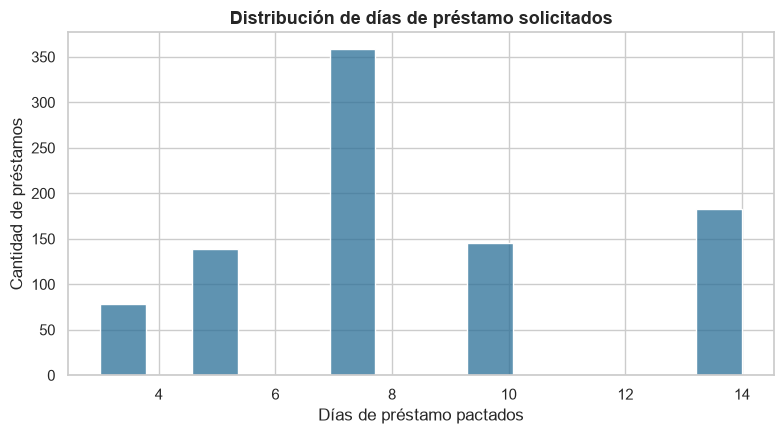

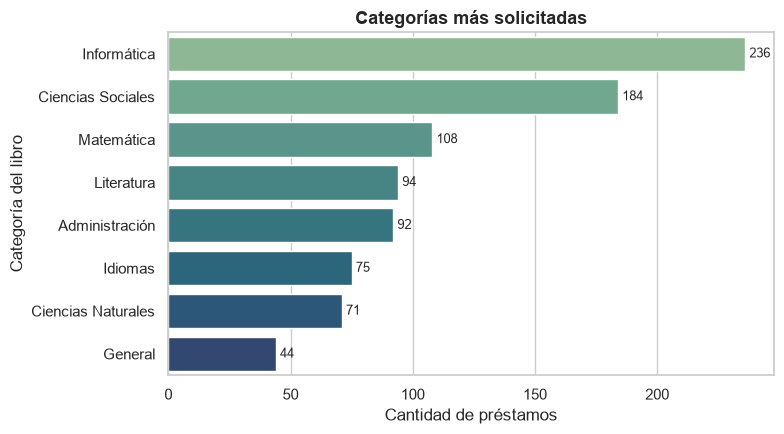

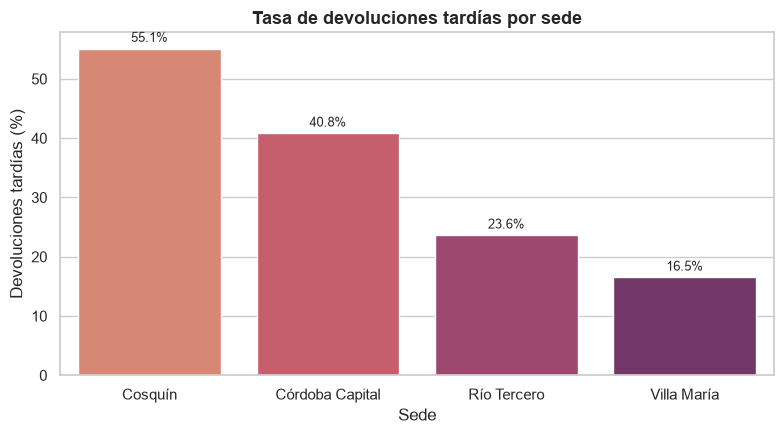

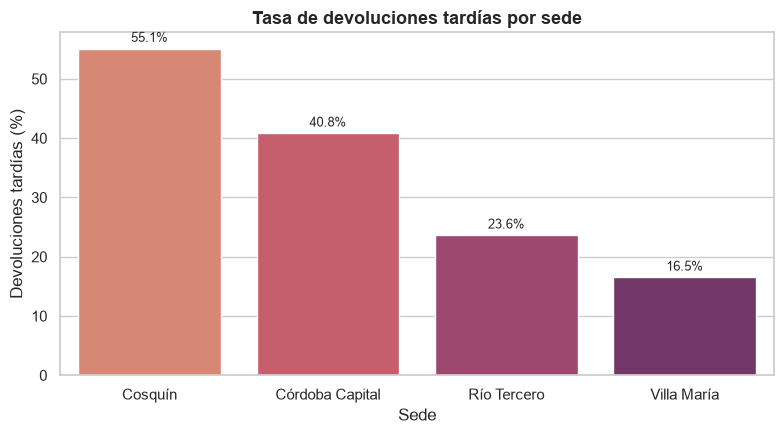

In [9]:
eda.grafico_dias_de_prestamo(prestamos, mostrar=True)
eda.grafico_categorias(prestamos, mostrar=True)
eda.grafico_mora_por_sede(prestamos, mostrar=True)

**Conclusiones del EDA**- Las categorías más solicitadas son **Informática** y **Ciencias Sociales**.- **Cosquín** es la sede con más préstamos y también la de mayor tasa de mora.- El promedio de demora en las devoluciones tardías es de **4 días**.- Los usuarios con demoras previas vuelven a demorarse: es la variable más influyente del modelo.

## 3. Modelo de riesgo de mora (RF11)Regresión logística dentro de un `Pipeline` que imputa nulos, codifica las variables categóricasy escala la numérica. El `SimpleImputer` y el `OneHotEncoder(handle_unknown="ignore")` son lacorrección del **BUG-04**.

In [10]:
modelo_entrenado, metricas = modelo.entrenar_modelo(prestamos)

print(f"Registros evaluados: {metricas['registros_evaluados']}")
print(f"Accuracy:  {metricas['accuracy']}")
print(f"Precisión: {metricas['precision']}")
print(f"Recall:    {metricas['recall']}")
print(f"Matriz de confusión: {metricas['matriz_confusion']}")

Registros evaluados: 210
Accuracy:  0.78
Precisión: 0.71
Recall:    0.65
Matriz de confusión: [[116, 20], [26, 48]]


In [11]:
modelo.importancia_de_variables(modelo_entrenado).head(10)

,Variable,Coeficiente
0,numericas__Demoras_Previas,1.183
1,categoricas__Sede_Cosquín,0.716
2,categoricas__Categoria_Libro_Informática,0.697
3,categoricas__Categoria_Libro_Ciencias Sociales,0.696
4,categoricas__Tipo_Usuario_Alumno,0.529
5,categoricas__Categoria_Libro_General,0.289
6,categoricas__Sede_Córdoba Capital,0.182
7,categoricas__Categoria_Libro_Idiomas,0.023
8,categoricas__Categoria_Libro_Matemática,-0.166
9,categoricas__Categoria_Libro_Literatura,-0.379


### BT-06 — Inferencia de la probabilidad de mora

In [12]:
caso = modelo.predecir_riesgo(modelo_entrenado, "Informática", "Alumno", 3)
print(caso["mensaje"])

Probabilidad estimada de mora: 78.7% - 🔴 RIESGO ALTO (Priorizar recordatorio)


### PI-03 — El pipeline tolera categorías vacías o desconocidas (BUG-04 corregido)

In [13]:
import numpy as np
import pandas as pd

lote = pd.DataFrame(
    [
        {"Categoria_Libro": "Informática", "Tipo_Usuario": "Alumno", "Sede": "Cosquín", "Demoras_Previas": 2},
        {"Categoria_Libro": np.nan, "Tipo_Usuario": "Alumno", "Sede": "Cosquín", "Demoras_Previas": 4},
        {"Categoria_Libro": "Categoría Nueva", "Tipo_Usuario": "Docente", "Sede": "Villa María", "Demoras_Previas": 0},
    ]
)

modelo.predecir_lote(modelo_entrenado, lote)

,Categoria_Libro,Tipo_Usuario,Sede,Demoras_Previas,Probabilidad_Mora,Nivel_Riesgo
0,Informática,Alumno,Cosquín,2,0.7690,ALTO
1,NaN,Alumno,Cosquín,4,0.8880,ALTO
2,Categoría Nueva,Docente,Villa María,0,0.0487,BAJO


## 4. Interfaz interactiva (RF6 a RF10)Pestañas disponibles: **Login · Catálogo · Reservas · Usuarios · Riesgo de mora · Notificaciones · Dashboard**.Datos de prueba para la demostración:| Para probar | Datos ||---|---|| Login correcto (CF-03) | `gino.lencina@ispc.edu.ar` / `Biblio2026*` || Usuario con mora (BT-02) | U-012 || Ejemplar sin stock (BT-07) | L-205 || Días fuera de rango (BT-01) | 0 o 15 días || Usuario con préstamo activo (CF-06 / BUG-03) | U-089 |

In [14]:
aplicacion = interfaz.AplicacionBiblioTech(prestamos, usuarios, catalogo, modelo_entrenado, metricas)
aplicacion.mostrar()

## 5. Verificación automática de los casos de pruebaEsta celda ejecuta la suite completa. El caso **CF-06** aparece como `expected failure`: es el**BUG-03**, que quedó abierto y documentado para la entrega final.

In [15]:
import unittest

cargador = unittest.TestLoader()
suite = cargador.discover(start_dir=str(raiz / "tests"), top_level_dir=str(raiz))
resultado = unittest.TextTestRunner(verbosity=2).run(suite)

print("")
print(f"Pruebas ejecutadas: {resultado.testsRun}")
print(f"Fallos: {len(resultado.failures)} | Errores: {len(resultado.errors)}")
print(f"Fallos esperados (defectos abiertos documentados): {len(resultado.expectedFailures)}")

test_conclusiones_del_eda (tests.test_datos.PruebasDeCalidadDeDatos.test_conclusiones_del_eda) ... 

ok


test_datos_de_prueba_de_los_casos_funcionales (tests.test_datos.PruebasDeCalidadDeDatos.test_datos_de_prueba_de_los_casos_funcionales) ... 

ok


test_la_tabla_del_modelo_no_tiene_valores_nulos (tests.test_datos.PruebasDeCalidadDeDatos.test_la_tabla_del_modelo_no_tiene_valores_nulos) ... 

...

ok


test_cf08_cierre_de_sesion (tests.test_negocio.PruebasDeReglasDeNegocio.test_cf08_cierre_de_sesion) ... 

ok


----------------------------------------------------------------------
Ran 36 tests in 0.156s

OK (expected failures=1)



Pruebas ejecutadas: 36
Fallos: 0 | Errores: 0
Fallos esperados (defectos abiertos documentados): 1


## 6. Cierre| Resultado | Valor ||---|---|| Casos de prueba planificados y ejecutados | 24 || Casos OK en la primera corrida | 20 (83,3 %) || Casos OK luego del re-testing | 23 (95,8 %) || Defectos detectados | 4 (BUG-01 a BUG-04) || Defectos cerrados | 3 || Defecto abierto | BUG-03 (baja de usuario con préstamo activo) || Accuracy del modelo | 0,78 |**Limitaciones conocidas del MVP**1. Los datos cargados durante la sesión viven en memoria: si se reinicia el entorno se pierden.2. El modelo se entrena sobre una muestra reducida (839 préstamos cerrados).3. Falta incorporar la variable de renovaciones y comparar contra un árbol de decisión.4. BUG-03 sigue abierto: la baja de usuarios no valida préstamos activos.Documentación completa en la carpeta [`docs/`](../docs) del repositorio.